# 03 · Exploratory Data Analysis
**Goal:** understand how campaigns, engagement levels, banners and placements perform, using the cleaned data.

Data: `data/processed/advertising_cleaned.csv` (created by notebook 02). Period: April–June (the file has no year).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

DATA_PATH = Path("..") / "data" / "processed" / "advertising_cleaned.csv"
df = pd.read_csv(DATA_PATH)
df["month"] = pd.Categorical(df["month"], ["April", "May", "June"], ordered=True)
df["user_engagement"] = pd.Categorical(df["user_engagement"], ["Low", "Medium", "High"], ordered=True)

VALUE_COLS = ["displays", "cost", "clicks", "revenue", "post_click_conversions", "post_click_sales_amount"]

def summarize(data, by):
    """Totals per group plus ratios calculated from the totals (not averages of row ratios)."""
    out = data.groupby(by, observed=True)[VALUE_COLS].sum()
    out["CTR_%"] = out["clicks"] / out["displays"] * 100
    out["CPC"] = out["cost"] / out["clicks"]
    out["CPM"] = out["cost"] / out["displays"] * 1000
    out["conv_per_click_%"] = out["post_click_conversions"] / out["clicks"] * 100
    out["CPA"] = out["cost"] / out["post_click_conversions"]
    out["net_revenue"] = out["revenue"] - out["cost"]
    out["ROI_%"] = out["net_revenue"] / out["cost"] * 100
    out["cost_share_%"] = out["cost"] / data["cost"].sum() * 100
    return out

**Metric definitions used in notebooks 03 and 04** (all ratios use group totals):

| Metric | Formula | Note |
|---|---|---|
| CTR | clicks / displays | click-through rate |
| CPC | cost / clicks | cost per click |
| CPM | cost / displays x 1000 | cost per 1,000 displays |
| Conversions per click | post_click_conversions / clicks | called a *rate* only loosely: in 328 rows conversions exceed clicks, so it can pass 100% |
| CPA | cost / post_click_conversions | cost per conversion |
| ROI | (revenue - cost) / cost | assumes `revenue` is the revenue earned from the ads, in the same currency as `cost` |

`post_click_sales_amount` is kept separate from `revenue` because the dataset has no data dictionary explaining how the two relate (sales are ~190x larger than total cost, so they are unlikely to be profit to the advertiser). No ROAS is calculated from it.

## 1. Overall KPIs

In [2]:
overall = summarize(df.assign(all_data="All campaigns"), "all_data")
overall.T.round(3)

all_data,All campaigns
displays,2.390143e+08
cost,1.751922e+05
clicks,2.492825e+06
revenue,2.762626e+05
post_click_conversions,6.517620e+05
post_click_sales_amount,3.271541e+07
CTR_%,1.043000e+00
CPC,7.000000e-02
CPM,7.330000e-01
conv_per_click_%,2.614600e+01


## 2. Campaign performance

In [3]:
campaign = summarize(df, "campaign_number")
campaign.round(3)

,displays,cost,clicks,revenue,post_click_conversions,post_click_sales_amount,CTR_%,CPC,CPM,conv_per_click_%,CPA,net_revenue,ROI_%,cost_share_%
campaign_number,,,,,,,,,,,,,,
camp 1,143309064,150688.122,1409126,230533.522,633082,3.101264e+07,0.983,0.107,1.051,44.927,0.238,79845.399,52.987,86.013
camp 2,45492269,17037.350,881158,34890.415,13767,1.167509e+06,1.937,0.019,0.375,1.562,1.238,17853.066,104.788,9.725
camp 3,50212928,7466.748,202541,10838.679,4913,5.352568e+05,0.403,0.037,0.149,2.426,1.520,3371.931,45.159,4.262


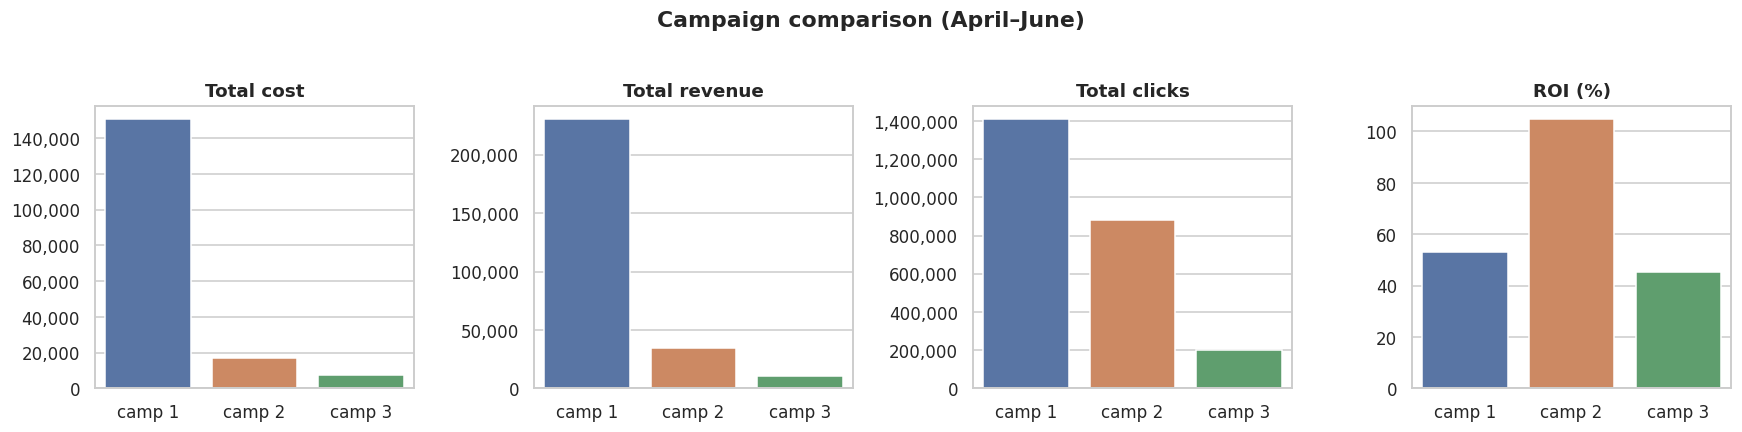

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
palette = sns.color_palette("deep", 3)
for ax, (col, title) in zip(axes, [("cost", "Total cost"), ("revenue", "Total revenue"),
                                     ("clicks", "Total clicks"), ("ROI_%", "ROI (%)")]):
    sns.barplot(data=campaign.reset_index(), x="campaign_number", y=col, hue="campaign_number",
                palette=palette, legend=False, ax=ax)
    ax.set_title(title); ax.set_xlabel(""); ax.set_ylabel("")
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
plt.suptitle("Campaign comparison (April–June)", y=1.03, fontweight="bold")
plt.tight_layout(); plt.show()

## 3. Time trends

In [5]:
month_summary = summarize(df, "month")
month_summary[["displays", "cost", "revenue", "clicks", "CTR_%", "CPC", "ROI_%"]].round(3)

,displays,cost,revenue,clicks,CTR_%,CPC,ROI_%
month,,,,,,,
April,128864381,88815.725,168342.961,1661115,1.289,0.053,89.542
May,66056607,55581.456,79488.685,539904,0.817,0.103,43.013
June,44093273,30795.039,28430.970,291806,0.662,0.106,-7.677


In [6]:
# Camp 2 only has April data, so monthly comparisons below show camp 1 and camp 3 only
monthly_campaign = summarize(df, ["campaign_number", "month"])
monthly_campaign[["cost", "revenue", "clicks", "CTR_%", "CPC", "ROI_%"]].round(3)

cost     revenue  clicks  CTR_%    CPC    ROI_%
campaign_number month                                                      
camp 1          April  68815.361  129230.445  699885  1.135  0.098   87.793
                May    53350.781   76013.642  475132  0.940  0.112   42.479
                June   28521.981   25289.434  234109  0.753  0.122  -11.334
camp 2          April  17037.350   34890.415  881158  1.937  0.019  104.788
camp 3          April   2963.015    4222.100   80072  0.369  0.037   42.493
                May     2230.675    3475.043   64772  0.418  0.034   55.784
                June    2273.058    3141.536   57697  0.444  0.039   38.207

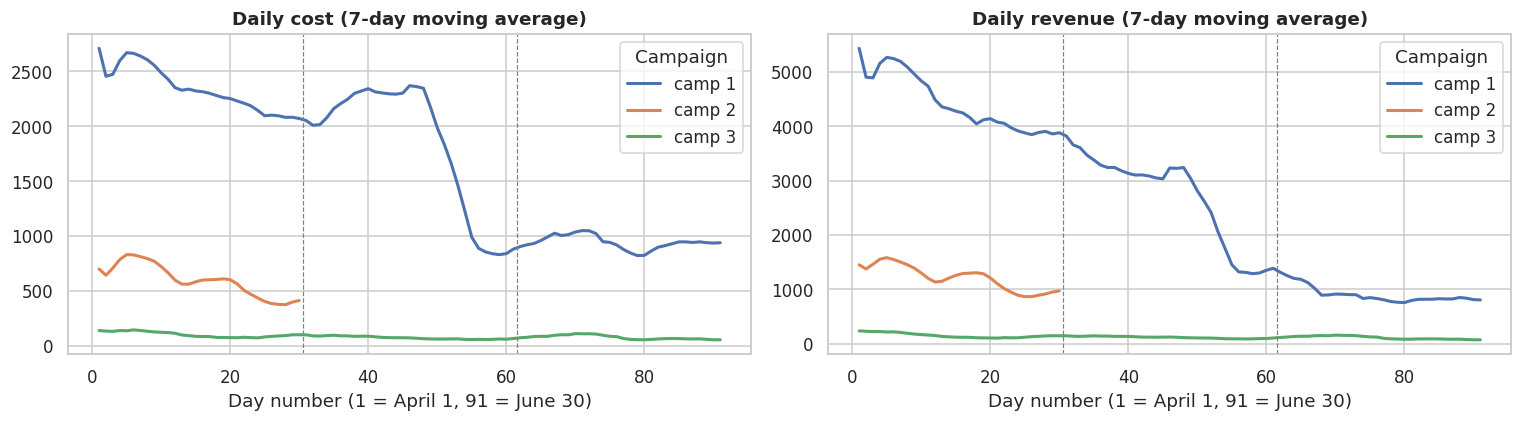

In [7]:
# Day-by-day view. The file has no year, so days are numbered 1-91 from April 1 to June 30.
daily = (df.groupby(["month_number", "day", "campaign_number"], as_index=False)[["cost", "revenue"]].sum())
daily["day_index"] = daily.groupby("campaign_number").cumcount() + 1
first_days = df.drop_duplicates(["month_number", "day"])[["month_number", "day"]].sort_values(["month_number", "day"])
first_days["day_index"] = range(1, len(first_days) + 1)
daily = daily.drop(columns="day_index").merge(first_days, on=["month_number", "day"])

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharex=True)
for ax, col, title in zip(axes, ["cost", "revenue"], ["Daily cost", "Daily revenue"]):
    for camp, grp in daily.groupby("campaign_number"):
        grp = grp.sort_values("day_index")
        ax.plot(grp["day_index"], grp[col].rolling(7, min_periods=1).mean(), label=camp, linewidth=2)
    ax.set_title(f"{title} (7-day moving average)"); ax.set_xlabel("Day number (1 = April 1, 91 = June 30)")
    ax.legend(title="Campaign")
for ax in axes:
    for boundary in (30.5, 61.5):  # April/May and May/June
        ax.axvline(boundary, color="grey", linestyle="--", linewidth=0.8)
plt.tight_layout(); plt.show()

## 4. User engagement level

In [8]:
engagement = summarize(df, "user_engagement")
engagement[["displays", "cost", "clicks", "revenue", "post_click_conversions", "CTR_%", "CPC", "CPA", "ROI_%", "cost_share_%"]].round(3)

,displays,cost,clicks,revenue,post_click_conversions,CTR_%,CPC,CPA,ROI_%,cost_share_%
user_engagement,,,,,,,,,,
Low,21504749,2691.764,101937,5144.394,1586,0.474,0.026,1.697,91.116,1.536
Medium,75533426,25701.611,1073517,58854.450,29257,1.421,0.024,0.878,128.991,14.671
High,141976086,146798.845,1317371,212263.772,620919,0.928,0.111,0.236,44.595,83.793


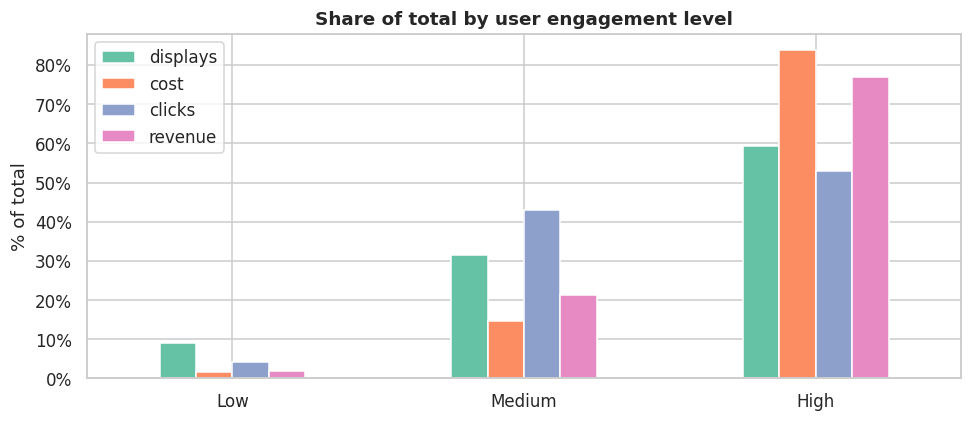

In [9]:
shares = engagement[["displays", "cost", "clicks", "revenue"]].div(engagement[["displays", "cost", "clicks", "revenue"]].sum()) * 100
shares.plot(kind="bar", figsize=(9, 4), rot=0, color=sns.color_palette("Set2", 4))
plt.title("Share of total by user engagement level"); plt.ylabel("% of total"); plt.xlabel("")
plt.gca().yaxis.set_major_formatter(mtick.PercentFormatter())
plt.tight_layout(); plt.show()

## 5. Banner sizes

In [10]:
banner = summarize(df, "banner").sort_values("cost", ascending=False)
banner[["displays", "cost", "clicks", "revenue", "CTR_%", "CPC", "ROI_%", "cost_share_%"]].round(3)

,displays,cost,clicks,revenue,CTR_%,CPC,ROI_%,cost_share_%
banner,,,,,,,,
240 x 400,65782211,56415.296,1113254,129930.135,1.692,0.051,130.310,32.202
728 x 90,76220124,52830.440,569606,64342.161,0.747,0.093,21.790,30.156
300 x 250,54838409,35438.527,411214,43171.353,0.750,0.086,21.820,20.228
160 x 600,28781603,17516.004,239560,23514.294,0.832,0.073,34.245,9.998
580 x 400,7189697,8978.573,120681,11193.143,1.679,0.074,24.665,5.125
670 x 90,5504972,3817.957,37203,4022.862,0.676,0.103,5.367,2.179
468 x 60,695126,192.651,1295,87.585,0.186,0.149,-54.537,0.110
800 x 250,2119,2.772,12,1.083,0.566,0.231,-60.951,0.002


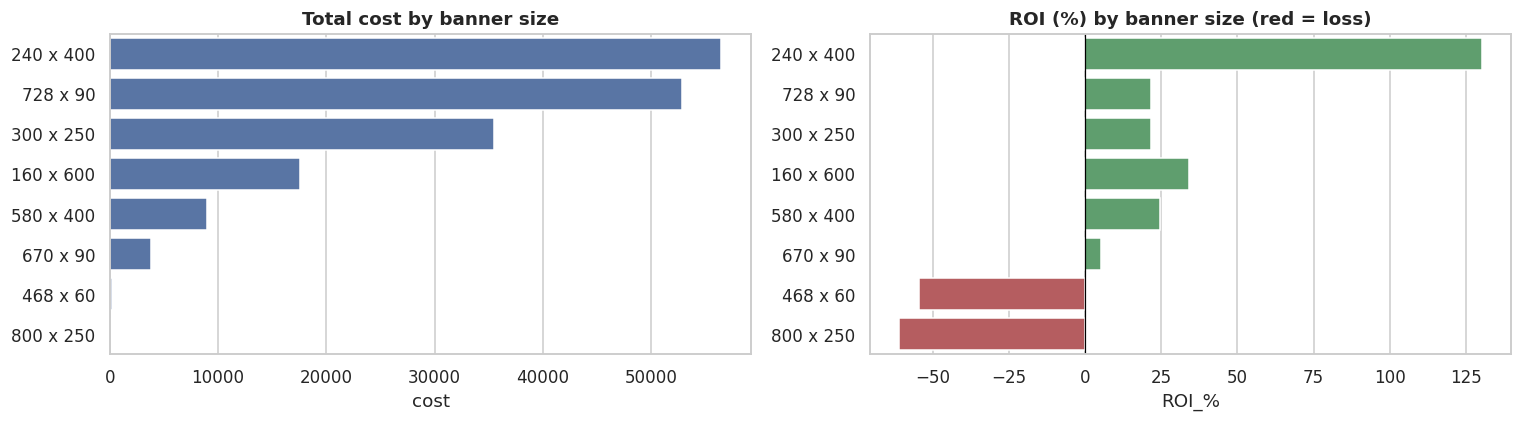

In [11]:
plot_data = banner.reset_index()
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(data=plot_data, y="banner", x="cost", color="#4C72B0", ax=axes[0])
axes[0].set_title("Total cost by banner size"); axes[0].set_ylabel("")
colors = ["#C44E52" if v < 0 else "#55A868" for v in plot_data["ROI_%"]]
sns.barplot(data=plot_data, y="banner", x="ROI_%", hue="banner", palette=colors, legend=False, ax=axes[1])
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_title("ROI (%) by banner size (red = loss)"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

## 6. Placements

In [12]:
placement = summarize(df, "placement").sort_values("cost", ascending=False)
placement[["displays", "cost", "clicks", "revenue", "CTR_%", "CPC", "CPA", "ROI_%", "cost_share_%"]].round(3)

,displays,cost,clicks,revenue,CTR_%,CPC,CPA,ROI_%,cost_share_%
placement,,,,,,,,,
mno,143159537,95006.242,993029,100458.345,0.694,0.096,0.361,5.739,54.230
ghi,59740398,62218.579,1247049,151548.102,2.087,0.050,0.185,143.574,35.514
def,28176283,14207.676,176095,15861.124,0.625,0.081,0.476,11.638,8.110
jkl,7692732,3629.565,75063,8254.489,0.976,0.048,0.174,127.424,2.072
abc,242142,127.376,1584,140.260,0.654,0.080,0.155,10.115,0.073
Unknown,3169,2.781,5,0.295,0.158,0.556,1.391,-89.379,0.002


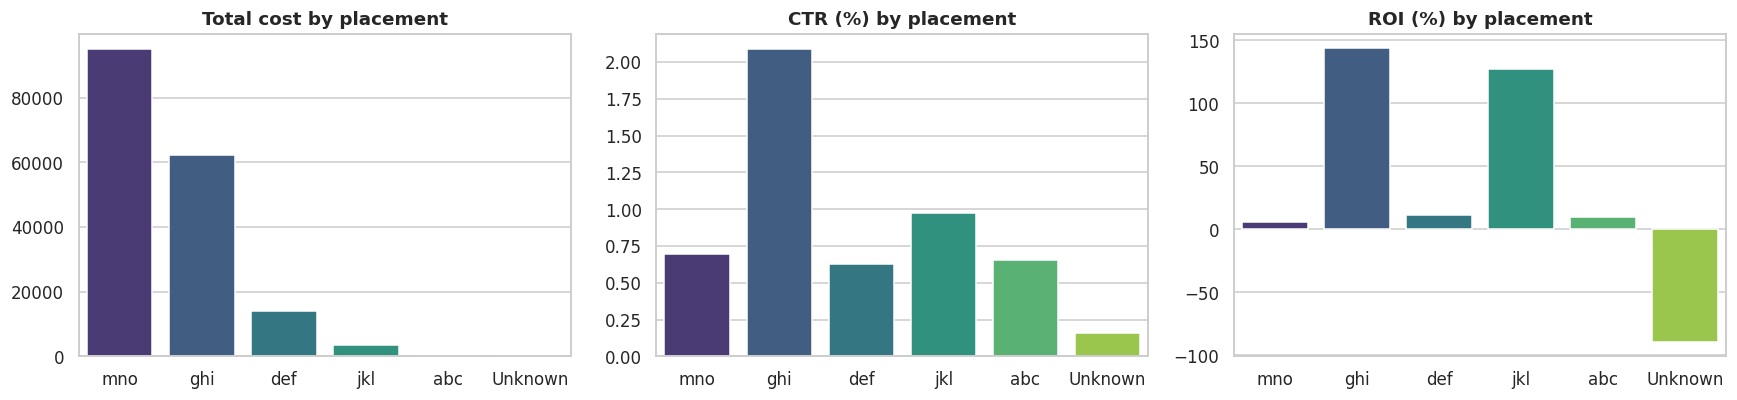

In [13]:
plot_data = placement.reset_index()
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, col, title in zip(axes, ["cost", "CTR_%", "ROI_%"], ["Total cost", "CTR (%)", "ROI (%)"]):
    sns.barplot(data=plot_data, x="placement", y=col, hue="placement", palette="viridis", legend=False, ax=ax)
    ax.set_title(f"{title} by placement"); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

## 7. Where is the money made or lost? (banner x placement)

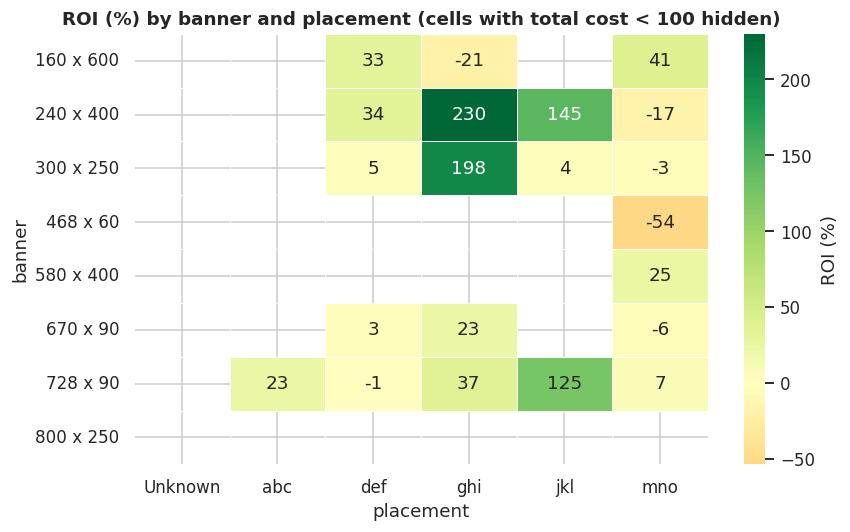

In [14]:
cell = df.groupby(["banner", "placement"], observed=True)[["cost", "revenue"]].sum()
cell["ROI_%"] = (cell["revenue"] - cell["cost"]) / cell["cost"] * 100
heat = cell["ROI_%"].where(cell["cost"] >= 100).unstack("placement")   # hide cells with under 100 total cost

plt.figure(figsize=(8, 5))
sns.heatmap(heat, annot=True, fmt=".0f", cmap="RdYlGn", center=0, linewidths=0.5,
            cbar_kws={"label": "ROI (%)"}, mask=heat.isna())
plt.title("ROI (%) by banner and placement (cells with total cost < 100 hidden)")
plt.tight_layout(); plt.show()

## 8. Distributions of individual rows

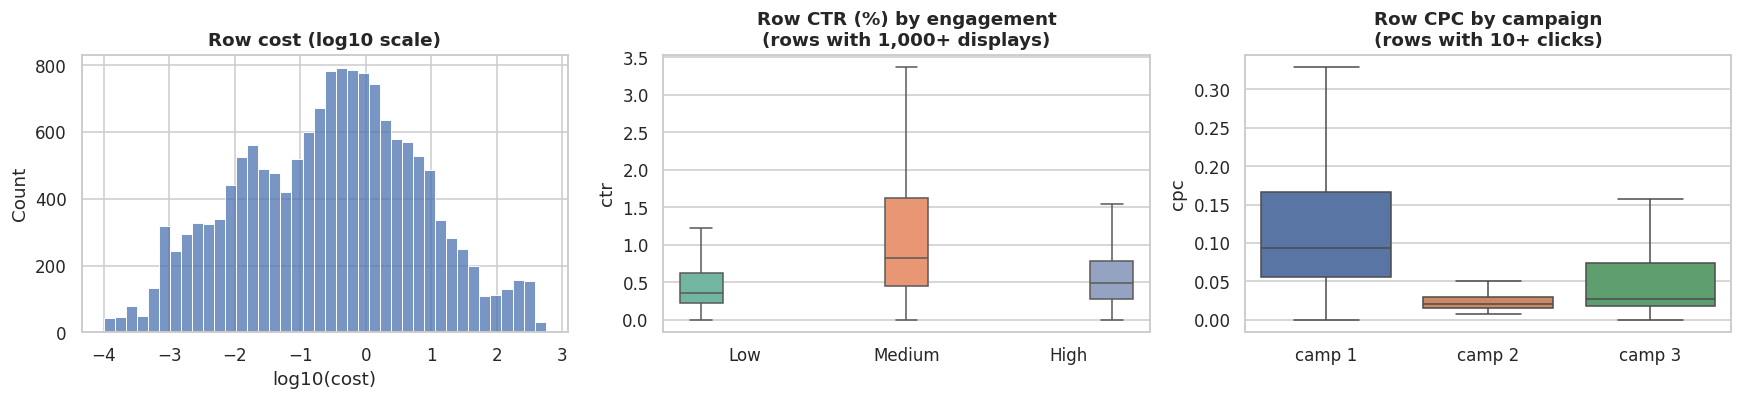

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
sns.histplot(np.log10(df.loc[df["cost"] > 0, "cost"]), bins=40, color="#4C72B0", ax=axes[0])
axes[0].set_title("Row cost (log10 scale)"); axes[0].set_xlabel("log10(cost)")

ctr_rows = df[df["displays"] >= 1000].assign(ctr=lambda d: d["clicks"] / d["displays"] * 100)
sns.boxplot(data=ctr_rows, x="user_engagement", y="ctr", hue="user_engagement", palette="Set2",
            showfliers=False, legend=False, ax=axes[1])
axes[1].set_title("Row CTR (%) by engagement\n(rows with 1,000+ displays)"); axes[1].set_xlabel("")

cpc_rows = df[df["clicks"] >= 10].assign(cpc=lambda d: d["cost"] / d["clicks"])
sns.boxplot(data=cpc_rows, x="campaign_number", y="cpc", hue="campaign_number", palette="deep",
            showfliers=False, legend=False, ax=axes[2])
axes[2].set_title("Row CPC by campaign\n(rows with 10+ clicks)"); axes[2].set_xlabel("")
plt.tight_layout(); plt.show()

## Key findings (from the tables and charts above)

1. **Scale is concentrated.** Camp 1 accounts for 86% of total cost ($150.7k of $175.2k). Within it, `High` engagement rows alone are 82% of all spend.
2. **Overall the ads earn more than they cost:** about $276k revenue on $175k cost (ROI roughly +58%), but the result is very uneven.
3. **Camp 2 is the most cost-efficient** (CPC $0.019, ROI about +105%, CTR 1.9%) yet only has April data and a small budget.
4. **Camp 1 is the weakest on cost per click** ($0.107, versus $0.019 and $0.037) and **Camp 3 has the lowest CTR** (0.40%).
5. **Time:** cost fell every month (April $88.8k → May $55.6k → June $30.8k); part of the April drop is simply Camp 2 not running afterwards, but Camp 1 alone also fell ($68.8k → $53.4k → $28.5k). Camp 1's ROI dropped from +88% in April to +42% in May and **-11% in June**.
6. **Engagement:** `High` engagement takes 84% of spend but returns the lowest ROI (+45%); `Medium` engagement has the highest ROI (+129%) on only 15% of spend.
7. **Banners:** `240 x 400` is the best large banner (ROI about +130%). The two tiny banners (`468 x 60`, `800 x 250`) lose money but represent almost no spend.
8. **Placements:** `ghi` and `jkl` have the best ROI (+144% and +127%); `mno` — the largest by spend (54%) — has an ROI of only about +6%.
9. **Data caution:** conversions per click looks very high for Camp 1 (about 45%), and conversions exceed clicks in 328 rows, so conversion-based metrics should be read as relative, not literal, measures.

Notebook 04 tests which of these patterns hold at campaign / engagement / banner / placement level.